In [5]:
import pandas as pd
import datetime as datetime
import matplotlib.pyplot as plt

df = pd.read_csv('employee_data.csv')
df.head()
df.info() #overview of datatypes and missing values
df.dtypes #just shows datatypes
df.isna().sum()#shows missing
df.describe()#shows statistical summaries, not very useful here because the actual numeric average that I want is presented as a string (Age as DOB instead of just the number)


<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 26 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   EmpID                       3000 non-null   int64
 1   FirstName                   3000 non-null   str  
 2   LastName                    3000 non-null   str  
 3   StartDate                   3000 non-null   str  
 4   ExitDate                    1533 non-null   str  
 5   Title                       3000 non-null   str  
 6   Supervisor                  3000 non-null   str  
 7   ADEmail                     3000 non-null   str  
 8   BusinessUnit                3000 non-null   str  
 9   EmployeeStatus              3000 non-null   str  
 10  EmployeeType                3000 non-null   str  
 11  PayZone                     3000 non-null   str  
 12  EmployeeClassificationType  3000 non-null   str  
 13  TerminationType             3000 non-null   str  
 14  TerminationDescript

,EmpID,LocationCode,Current Employee Rating
count,3000.000000,3000.000000,3000.000000
mean,2500.500000,44997.180667,2.969000
std,866.169729,29987.331783,1.015078
min,1001.000000,1013.000000,1.000000
25%,1750.750000,17546.000000,2.000000
50%,2500.500000,44150.500000,3.000000
75%,3250.250000,71481.250000,3.000000
max,4000.000000,98052.000000,5.000000


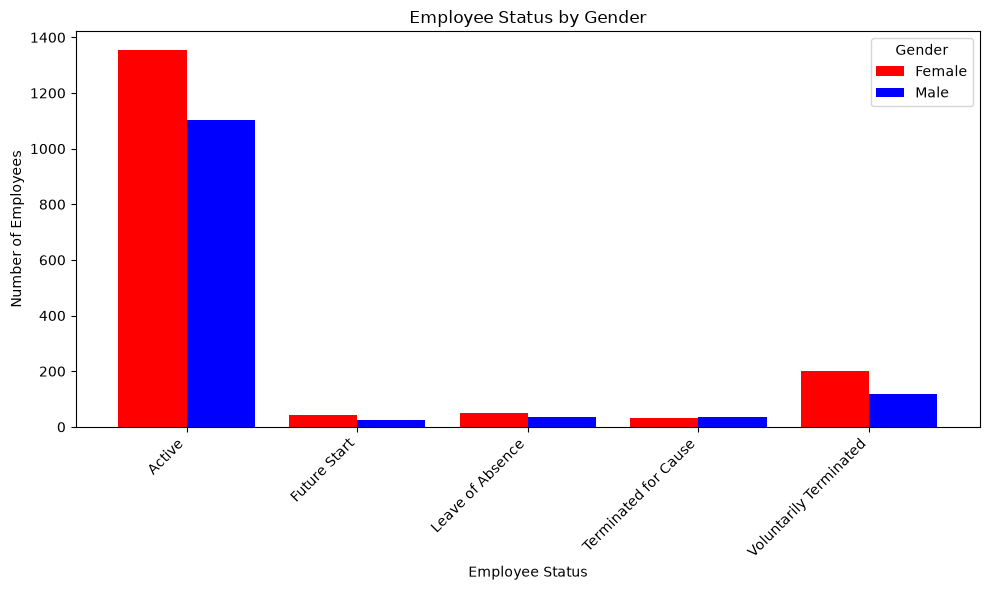

In [2]:
#Data by Gender
#The statuses are: Active, Voluntarily Terminated, Future Start, Leave of Absence, Terminated for Cause
#Turn over describes those who left the company, include Voluntarily Terminated and Terminated for Cause.
#Active, Leave of Absence, and Future start will be considered employed
#not sure whether to exclude future start
#genderAt = df.groupby('GenderCode')['EmployeeStatus'].agg(Total_Employed = 'count', resigned = lambda x: (x == 'Voluntarily Terminated').sum())
#genderAt['attrition_rate_%'] = (genderAt['resigned']/genderAt['Total_Employed'])*100
#genderAt

genderAt = pd.crosstab(df['GenderCode'], df['EmployeeStatus'], margins=False)
genderAt['Total_Employed'] = genderAt.sum(axis=1)#"total_employed" is actually just the amount of people in the dataset, like for the female colum its the total amount of females
genderAt['attrition_rate_%'] = (genderAt.get('Voluntarily Terminated',0) + genderAt.get('Terminated for Cause',0))/genderAt['Total_Employed']*100 #so is this correct? should be the number of people terminated period, divided by the total amount of people in the dataset
genderAt
#now make a bar chart or pie chart

plot_data = genderAt.drop(columns = ['Total_Employed', 'attrition_rate_%'], errors='ignore')
plot_data.T.plot(kind = 'bar', figsize = (10, 6), color = ['red', 'blue'], width = 0.8)
plt.xlabel('Employee Status')
plt.ylabel('Number of Employees')
plt.title('Employee Status by Gender')
plt.xticks(rotation=45, ha='right')
plt.legend(title = 'Gender', labels =['Female', 'Male'])
plt.tight_layout()
plt.show()




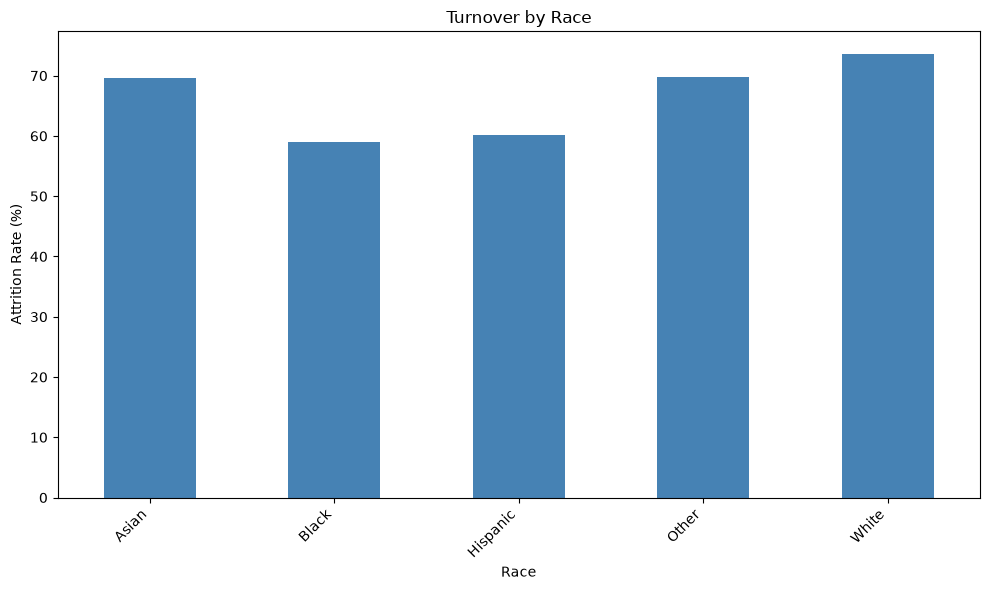

In [3]:
#By Race
RaceAttrition =pd.crosstab(df['RaceDesc'], df['EmployeeStatus'], margins=False)
RaceAttrition['Total_Value'] = RaceAttrition.sum(axis=1)#amount of people in the dataset for that row
RaceAttrition['attrition_rate_%'] = (RaceAttrition.get('Voluntarily Terminated',0) + RaceAttrition.get('Terminated for Cause',0))/RaceAttrition['Total_Value']*100 #so is this correct? should be the number of people terminated period, divided by the total amount of people in the dataset
RaceAttrition

RaceAttrition = pd.crosstab(df['RaceDesc'],df['EmployeeStatus'],margins=False)

RaceAttrition['Total_Value'] = RaceAttrition.sum(axis=1)

RaceAttrition['attrition_rate_%'] = RaceAttrition.get('Voluntarily Terminated', 0)+ RaceAttrition.get('Terminated for Cause', 0) / RaceAttrition['Total_Value'] * 100

# Create the bar graph
RaceAttrition['attrition_rate_%'].plot(kind='bar',color='steelblue',figsize=(10, 6))

plt.title('Turnover by Race')
plt.xlabel('Race')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#plot_data = RaceAttrition.drop(columns = ['Total_Value', 'attrition_rate_%'], errors='ignore')
#plot_data.T.plot(kind = 'bar', figsize = (10, 6), color = ['/','|','-','.','+'], width = 0.8)
#plt.xlabel('Employee Status')
#plt.ylabel('Number of Employees')
#plt.title('Employee Status by Race')
#plt.xticks(rotation=45, ha='right')
#plt.legend(title = 'Gender', labels =['Female', 'Male'])
#plt.tight_layout()
#plt.show()


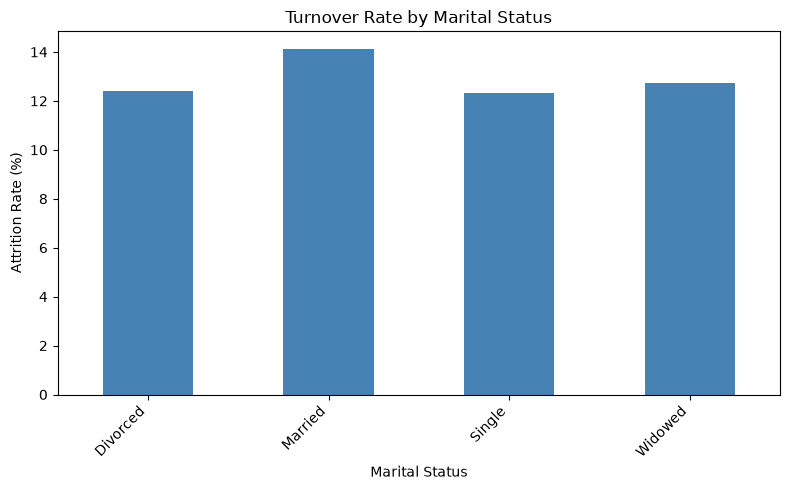

In [4]:
#Marital Status
MariAttrition = pd.crosstab(df['MaritalDesc'], df['EmployeeStatus'], margins=False)
MariAttrition['Total_Value'] = MariAttrition.sum(axis = 1)
MariAttrition['attrition_rate_%'] = (MariAttrition.get('Voluntarily Terminated',0) + MariAttrition.get('Terminated for Cause',0))/MariAttrition['Total_Value']*100
MariAttrition

MariAttrition = pd.crosstab(
    df['MaritalDesc'],
    df['EmployeeStatus'],
    margins=False
)

MariAttrition['Total_Value'] = MariAttrition.sum(axis=1)

MariAttrition['attrition_rate_%'] = (
    MariAttrition.get('Voluntarily Terminated', 0)
    + MariAttrition.get('Terminated for Cause', 0)
) / MariAttrition['Total_Value'] * 100

# Create the bar chart
MariAttrition['attrition_rate_%'].plot(
    kind='bar',
    color='steelblue',
    figsize=(8, 5)
)

plt.title('Turnover Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
#plt.figure(figsize = (8,8))
#plt.pie(MariAttrition['attrition_rate_%'], autopct='%1.1f%%', startangle=90)
#plt.title('Percentage Turnover by Marital Status')
#plt.legend(title = 'Marital Status', labels =['Divorced', 'Married','Single', 'Widowed'])
#plt.axis('equal')
#plt.show()

Total employee records: 3000
Successfully parsed DOBs: 3000
Invalid or missing DOBs: 0
Average Employee Age: 54.64

Turnover by Age Group:
          Employees  Left  Turnover Rate (%)
AgeGroup                                    
18-19             0     0                NaN
20-29           249    32              12.85
30-39           539    65              12.06
40-49           466    69              14.81
50-59           466    61              13.09
60-69           507    61              12.03
70-79           504    62              12.30
80-89           269    37              13.75
90+               0     0                NaN


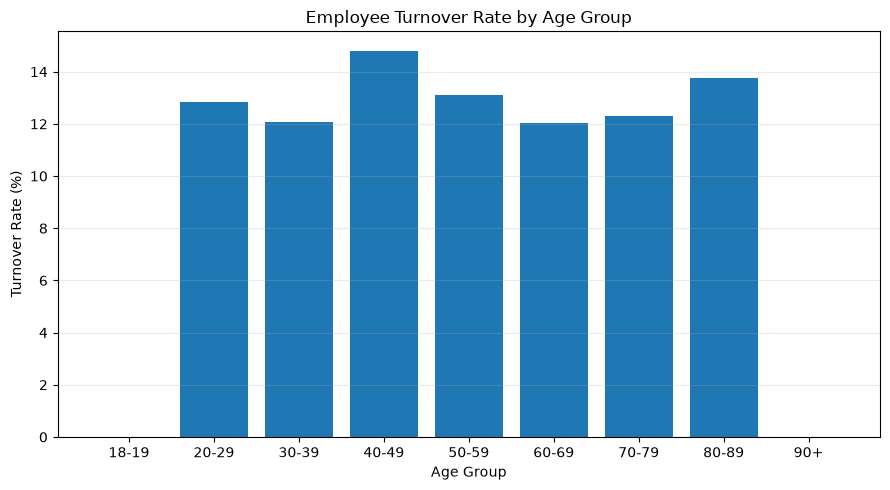

In [20]:
#Age
import pandas as pd
import datetime as datetime
import matplotlib.pyplot as plt

df = pd.read_csv('employee_data.csv')
# Preserve DOB as text, then parse using DD-MM-YYYY
df["DOB"] = pd.to_datetime(
    df["DOB"].astype("string").str.strip(),
    format="%d-%m-%Y",
    errors="coerce"
)

# Check DOB parsing
print("Total employee records:", len(df))
print("Successfully parsed DOBs:", df["DOB"].notna().sum())
print("Invalid or missing DOBs:", df["DOB"].isna().sum())

# Calculate age as of November 3, 2026
as_of = pd.Timestamp("2026-11-03")

df["Age"] = (
    (as_of - df["DOB"]).dt.days / 365.2425
).apply(lambda x: int(x) if pd.notna(x) else pd.NA)

# Calculate average age
average_age = df["Age"].dropna().mean()

print(f"Average Employee Age: {average_age:.2f}")

# Identify employees who left
left_statuses = [
    "Voluntarily Terminated",
    "Terminated for Cause"
]

df["Left"] = df["EmployeeStatus"].isin(left_statuses)

# Assign age groups
def age_group(age):
    if pd.isna(age):
        return None
    elif 18 <= age <= 19:
        return "18-19"
    elif 20 <= age <= 29:
        return "20-29"
    elif 30 <= age <= 39:
        return "30-39"
    elif 40 <= age <= 49:
        return "40-49"
    elif 50 <= age <= 59:
        return "50-59"
    elif 60 <= age <= 69:
        return "60-69"
    elif 70 <= age <= 79:
        return "70-79"
    elif 80 <= age <= 89:
        return "80-89"
    elif age >= 90:
        return "90+"
    else:
        return None


df["AgeGroup"] = df["Age"].apply(age_group)

# Keep requested age groups
order = ["18-19", "20-29", "30-39", "40-49", "50-59", "60-69","70-79", "80-89","90+"]

eligible = df[df["AgeGroup"].notna()]

# Calculate employee counts and departures
summary = eligible.groupby("AgeGroup").agg(
    Employees=("EmpID", "size"),
    Left=("Left", "sum")
).reindex(order, fill_value=0)

# Calculate turnover percentage
summary["Turnover Rate (%)"] = (
    summary["Left"] /
    summary["Employees"].replace(0, float("nan")) * 100
)

# Display results
print("\nTurnover by Age Group:")
print(summary.round(2))

# Plot bar graph
plot_rates = summary["Turnover Rate (%)"].fillna(0)

plt.figure(figsize=(9, 5))
plt.bar(plot_rates.index, plot_rates.values)

plt.title("Employee Turnover Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Turnover Rate (%)")
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("turnover_by_age_group.png", dpi=160)
plt.show()